# Assignment 06: Descriptive Statistics

**The final output dataframe should include the following for each patient:**
- Patient Age
- Patient Height
- Patient Weight
- Patient BMI (see the BMI Formula here)
- Patient Sex
- Patient eGFR

In [33]:
#IMPORTS
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
CSV_PATH = "https://ruby.ils.unc.edu/~kibria/chip705_2026_fall/patient_demographics.csv"
JSON_PATH = "https://ruby.ils.unc.edu/~kibria/chip705_2026_fall/cmp.json"


### PAT DATAFRAME (DF)

In [8]:
df_pat_demog = pd.read_csv(CSV_PATH)
df_pat_demog.head(12)



,sex,first_name,last_name,street_address,city,state,zip_code,home_number,mobile_number,age,height_inches,weight_lbs,patient_id
0,M,Donald,Morris,5627 Knapp Gardens Apt. 460,Catherinefort,NC,28612,5293304512,313.959.9764,26,84,199,762116383
1,M,Brandon,Webster,264 Carter Meadow,North Connie,NC,20502,NaN,001-372-631-0549,57,76,235,E36334296
2,F,Jocelyn,Calderon,02528 Delacruz Mount,Campbellfurt,NC,46130,NaN,001-432-988-3642x545,25,74,298,792717195
3,F,Ashley,Ortega,2423 Davis Gateway Apt. 325,Port Williamfort,NC,16743,001-301-264-4827x71461,957-479-1917x5734,58,80,147,R91829145
4,M,Allen,Lambert,9506 Victoria Terrace Suite 486,East Laura,NC,48045,NaN,480.912.8263,41,78,250,K16719467
5,M,George,Flores,392 Shannon Ridges,Martinezton,NC,12782,NaN,849.640.4719,44,80,143,O53151631
6,F,Miranda,Williams,017 David Harbor,Shawnshire,NC,8161,(540)908-2100x223,001-740-605-1429x964,65,65,222,396698831
7,M,Ryan,Ellison,03365 Mallory Summit Apt. 436,Randallstad,NC,70469,NaN,001-215-692-9323x1454,18,69,207,345380060
8,M,David,Short,934 Smith Estate,West Jenniferstad,NC,95943,341.817.6402x3211,001-949-834-8800x09726,32,66,265,T25445880
9,M,Robert,Kennedy,32873 Newman Knolls,East Ashleeport,NC,31401,(811)814-7536x2407,+1-251-719-5935x07307,52,72,179,606320215


In [9]:
df_demo = df_pat_demog.copy()[["patient_id", "age", "height_inches", "weight_lbs", "sex"]]
df_demo.head(10)

,patient_id,age,height_inches,weight_lbs,sex
0,762116383,26,84,199,M
1,E36334296,57,76,235,M
2,792717195,25,74,298,F
3,R91829145,58,80,147,F
4,K16719467,41,78,250,M
5,O53151631,44,80,143,M
6,396698831,65,65,222,F
7,345380060,18,69,207,M
8,T25445880,32,66,265,M
9,606320215,52,72,179,M


In [10]:
bmis = []

for idx,row in df_demo.iterrows():
    bmi = (703*row["weight_lbs"]) / row["height_inches"]**2
    bmis.append(bmi)

bmis[:10]

[19.826672335600907,
 28.601973684210527,
 38.25675675675676,
 16.14703125,
 28.887245233399078,
 15.70765625,
 36.93869822485207,
 30.565217391304348,
 42.76744719926538,
 24.274112654320987]

In [11]:
### Add new column to dataframe.
df_demo["bmi"] = bmis
df_demo.head(10)

,patient_id,age,height_inches,weight_lbs,sex,bmi
0,762116383,26,84,199,M,19.826672
1,E36334296,57,76,235,M,28.601974
2,792717195,25,74,298,F,38.256757
3,R91829145,58,80,147,F,16.147031
4,K16719467,41,78,250,M,28.887245
5,O53151631,44,80,143,M,15.707656
6,396698831,65,65,222,F,36.938698
7,345380060,18,69,207,M,30.565217
8,T25445880,32,66,265,M,42.767447
9,606320215,52,72,179,M,24.274113


In [12]:
import json
from urllib.request import urlopen
with urlopen(JSON_PATH) as file:
    cmp_data = json.load(file)

print(type(cmp_data))
print(list(cmp_data.keys())[:5])

<class 'dict'>
['762116383', 'E36334296', '792717195', 'R91829145', 'K16719467']


In [13]:
creatinine_list = [x[5]["patient_measure"] for x in cmp_data.values()]
patient_ids = list(cmp_data.keys())


In [14]:
creatinine_list[0]

1.6471847262925066

In [16]:
df_cmp = pd.DataFrame({"patient_id":patient_ids,"creatinine_level":creatinine_list})
df_cmp
df_combined = pd.merge(
    df_demo,
    df_cmp,
    on="patient_id",
    how="inner"
)

df_combined.head(10)


,patient_id,age,height_inches,weight_lbs,sex,bmi,creatinine_level
0,762116383,26,84,199,M,19.826672,1.647185
1,E36334296,57,76,235,M,28.601974,1.947691
2,792717195,25,74,298,F,38.256757,1.606701
3,R91829145,58,80,147,F,16.147031,0.570993
4,K16719467,41,78,250,M,28.887245,1.489089
5,O53151631,44,80,143,M,15.707656,1.071103
6,396698831,65,65,222,F,36.938698,0.871145
7,345380060,18,69,207,M,30.565217,1.714051
8,T25445880,32,66,265,M,42.767447,0.402204
9,606320215,52,72,179,M,24.274113,1.656279


In [17]:
cmp_data["762116383"][5]

{'measure': 'Creatinine',
 'low_normal': 0.6,
 'high_normal': 1.3,
 'unit': 'mg/dL',
 'patient_measure': 1.6471847262925066}

In [18]:
def calculate_egfr(age, sex, creatinine):
    if sex == "F":
        k = 0.7
        a = -0.241
        sex_factor = 1.012
    else:
        k = 0.9
        a = -0.302
        sex_factor = 1

    low = min(creatinine / k, 1)
    high = max(creatinine / k, 1)

    age = float(age)

    egfr = 142 * (low**a) * (high**-1.200) * (0.9938**age) * sex_factor

    return egfr

In [19]:
df_combined["egfr"] = df_combined.apply(
    lambda row: calculate_egfr(
        row["age"],
        row["sex"],
        row["creatinine_level"]
    ),
    axis=1
)

df_combined.head(10)

,patient_id,age,height_inches,weight_lbs,sex,bmi,creatinine_level,egfr
0,762116383,26,84,199,M,19.826672,1.647185,58.487410
1,E36334296,57,76,235,M,28.601974,1.947691,39.445537
2,792717195,25,74,298,F,38.256757,1.606701,45.387805
3,R91829145,58,80,147,F,16.147031,0.570993,105.227915
4,K16719467,41,78,250,M,28.887245,1.489089,60.135801
5,O53151631,44,80,143,M,15.707656,1.071103,87.647125
6,396698831,65,65,222,F,36.938698,0.871145,73.775514
7,345380060,18,69,207,M,30.565217,1.714051,58.604723
8,T25445880,32,66,265,M,42.767447,0.402204,148.420679
9,606320215,52,72,179,M,24.274113,1.656279,49.427287


In [20]:
def calculate_egfr(age, sex, creatinine):
    if sex == "F":
        k = 0.7
        a = -0.241
        sex_factor = 1.012
    elif sex == "M":
        k = 0.9
        a = -0.302
        sex_factor = 1
    else:
        raise ValueError(f"Unexpected sex value: {sex}")

    low = min(creatinine / k, 1)
    high = max(creatinine / k, 1)

    age = float(age)

    egfr = 142 * (low**a) * (high**-1.200) * (0.9938**age) * sex_factor

    return egfr

In [21]:
df_combined["sex"].value_counts(dropna=False)

sex
M    64
F    36
Name: count, dtype: int64

In [22]:
df_combined["egfr"] = df_combined.apply(
    lambda row: calculate_egfr(
        row["age"],
        row["sex"],
        row["creatinine_level"]
    ),
    axis=1
)

df_combined.head(10)

,patient_id,age,height_inches,weight_lbs,sex,bmi,creatinine_level,egfr
0,762116383,26,84,199,M,19.826672,1.647185,58.487410
1,E36334296,57,76,235,M,28.601974,1.947691,39.445537
2,792717195,25,74,298,F,38.256757,1.606701,45.387805
3,R91829145,58,80,147,F,16.147031,0.570993,105.227915
4,K16719467,41,78,250,M,28.887245,1.489089,60.135801
5,O53151631,44,80,143,M,15.707656,1.071103,87.647125
6,396698831,65,65,222,F,36.938698,0.871145,73.775514
7,345380060,18,69,207,M,30.565217,1.714051,58.604723
8,T25445880,32,66,265,M,42.767447,0.402204,148.420679
9,606320215,52,72,179,M,24.274113,1.656279,49.427287


In [23]:
df_combined["egfr"].describe()

count    100.000000
mean      84.327789
std       33.407204
min       34.421994
25%       56.102626
50%       79.305642
75%      113.267255
max      163.193577
Name: egfr, dtype: float64

In [24]:
df_final = df_combined[
    ["age", "height_inches", "weight_lbs", "bmi", "sex", "egfr"]
].copy()

df_final.columns = [
    "Patient Age",
    "Patient Height",
    "Patient Weight",
    "Patient BMI",
    "Patient Sex",
    "Patient eGFR"
]

df_final.head(10)

,Patient Age,Patient Height,Patient Weight,Patient BMI,Patient Sex,Patient eGFR
0,26,84,199,19.826672,M,58.487410
1,57,76,235,28.601974,M,39.445537
2,25,74,298,38.256757,F,45.387805
3,58,80,147,16.147031,F,105.227915
4,41,78,250,28.887245,M,60.135801
5,44,80,143,15.707656,M,87.647125
6,65,65,222,36.938698,F,73.775514
7,18,69,207,30.565217,M,58.604723
8,32,66,265,42.767447,M,148.420679
9,52,72,179,24.274113,M,49.427287


In [25]:
df_final.shape

(100, 6)

In [26]:
df_filtered = df_combined[df_combined["egfr"] <= 65].copy()

df_filtered.head(10)

,patient_id,age,height_inches,weight_lbs,sex,bmi,creatinine_level,egfr
0,762116383,26,84,199,M,19.826672,1.647185,58.487410
1,E36334296,57,76,235,M,28.601974,1.947691,39.445537
2,792717195,25,74,298,F,38.256757,1.606701,45.387805
4,K16719467,41,78,250,M,28.887245,1.489089,60.135801
7,345380060,18,69,207,M,30.565217,1.714051,58.604723
9,606320215,52,72,179,M,24.274113,1.656279,49.427287
10,L64281921,44,62,144,M,26.335068,1.936273,43.070011
14,U53337753,59,63,166,F,29.402368,1.444387,41.745227
16,R49737210,24,81,212,M,22.715440,1.856009,51.316727
23,329933985,53,80,278,M,30.536562,1.684216,48.144720


In [27]:
df_filtered.shape

(41, 8)

In [28]:
df_stats = df_filtered[["age", "height_inches", "weight_lbs"]].describe()

df_stats

,age,height_inches,weight_lbs
count,41.000000,41.000000,41.000000
mean,41.439024,72.634146,221.902439
std,14.615144,7.415376,38.822548
min,18.000000,61.000000,144.000000
25%,29.000000,65.000000,194.000000
50%,40.000000,73.000000,224.000000
75%,56.000000,79.000000,247.000000
max,64.000000,84.000000,298.000000


In [29]:
bins = [0, 18.5, 25, 30, float("inf")]

labels = [
    "Underweight",
    "Normal Weight",
    "Overweight",
    "Obese"
]

df_filtered["bmi_category"] = pd.cut(
    df_filtered["bmi"],
    bins=bins,
    labels=labels,
    right=False
)

df_filtered[["bmi", "bmi_category"]].head(10)

,bmi,bmi_category
0,19.826672,Normal Weight
1,28.601974,Overweight
2,38.256757,Obese
4,28.887245,Overweight
7,30.565217,Obese
9,24.274113,Normal Weight
10,26.335068,Overweight
14,29.402368,Overweight
16,22.715440,Normal Weight
23,30.536562,Obese


In [30]:
df_filtered["bmi_category"].value_counts()

bmi_category
Obese            20
Overweight       11
Normal Weight     9
Underweight       1
Name: count, dtype: int64

In [31]:
avg_egfr_bmi = df_filtered.groupby(
    "bmi_category",
    observed=False
)["egfr"].mean()

avg_egfr_bmi

bmi_category
Underweight      63.770279
Normal Weight    51.978340
Overweight       53.227006
Obese            50.951178
Name: egfr, dtype: float64

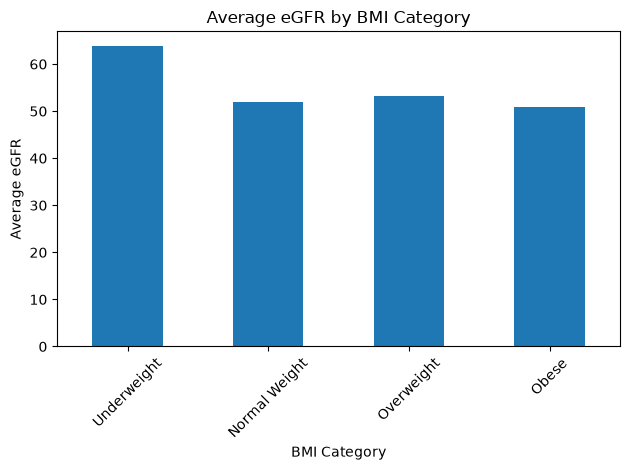

In [34]:
avg_egfr_bmi.plot(kind="bar")

plt.title("Average eGFR by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average eGFR")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

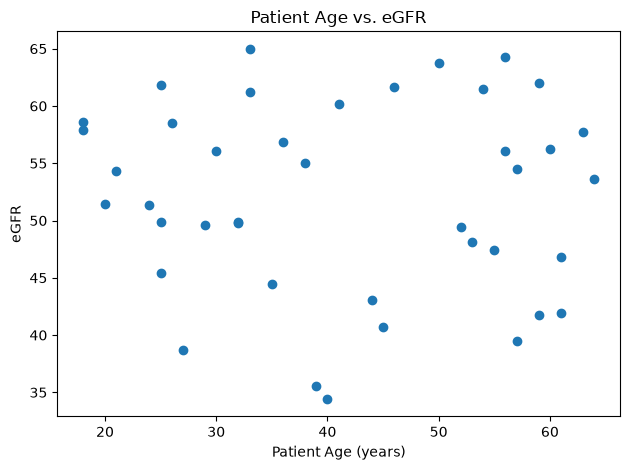

In [35]:
plt.scatter(df_filtered["age"], df_filtered["egfr"])

plt.title("Patient Age vs. eGFR")
plt.xlabel("Patient Age (years)")
plt.ylabel("eGFR")
plt.tight_layout()
plt.show()

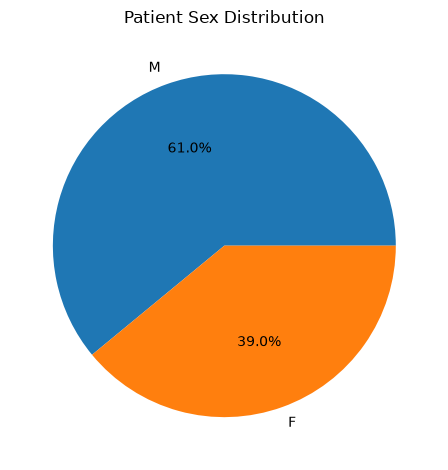

In [36]:
sex_counts = df_filtered["sex"].value_counts()

sex_counts.plot(kind="pie", autopct="%1.1f%%")

plt.title("Patient Sex Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [37]:
df_final.columns.tolist()

['Patient Age',
 'Patient Height',
 'Patient Weight',
 'Patient BMI',
 'Patient Sex',
 'Patient eGFR']